# Boiling an Egg: Realistic FEM Model

This notebook builds on the simple spherical model from Notebook 01 by introducing
three key improvements:

1. **Egg-shaped geometry** -- a realistic axisymmetric egg profile replaces the
   semicircular cross-section.
2. **Separate yolk and white regions** -- the mesh contains two subdomains with
   distinct material properties.
3. **Temperature-dependent material properties** -- density, thermal conductivity,
   and specific heat all vary with temperature, giving a more faithful
   representation of the cooking process.

We solve the axisymmetric transient heat equation using backward Euler time
integration on a triangular finite-element mesh generated by Gmsh.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from skfem import Basis, ElementTriP1
from skfem.visuals.matplotlib import plot as skfem_plot

from egg_fem.geometry import egg_profile, create_egg_mesh
from egg_fem.materials import (
    egg_white_properties,
    egg_yolk_properties,
    T_BOILING,
    T_ROOM,
    WHITE_DENATURATION_K,
    YOLK_DENATURATION_K,
    YOLK_FULL_SET_K,
)
from egg_fem.solver import HeatSolver

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
})

## Egg Geometry

The egg shape is parameterised by a modified sine/cosine curve that gives a
slightly pointed top.  We first visualise the profile and then generate the
full triangulated mesh with separate yolk and white subdomains.

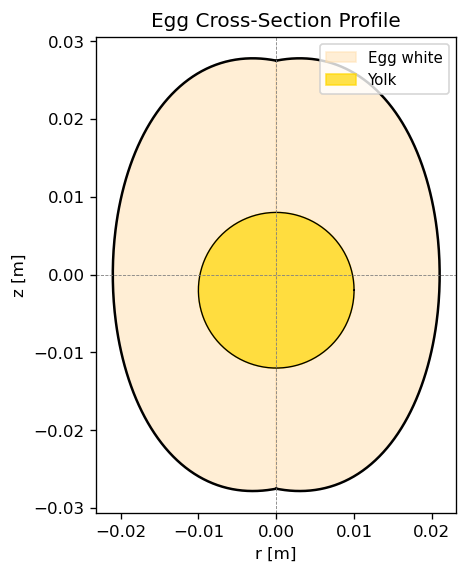

In [2]:
# --- Egg profile outline with yolk ---
r_prof, z_prof = egg_profile(n=300)

fig, ax = plt.subplots(figsize=(4, 6))
# Fill the egg outline
ax.fill(r_prof, z_prof, color='navajowhite', alpha=0.5, label='Egg white')
ax.fill(-r_prof, z_prof, color='navajowhite', alpha=0.5)
# Plot the outline
ax.plot(r_prof, z_prof, 'k-', lw=1.5)
ax.plot(-r_prof, z_prof, 'k-', lw=1.5)

# Yolk as a semicircle (full circle since we mirror)
yolk_radius = 0.010
yolk_center_z = -0.002
theta = np.linspace(0, 2 * np.pi, 200)
r_yolk = yolk_radius * np.cos(theta)
z_yolk = yolk_center_z + yolk_radius * np.sin(theta)
ax.fill(r_yolk, z_yolk, color='gold', alpha=0.7, label='Yolk')
ax.plot(r_yolk, z_yolk, 'k-', lw=0.8)

ax.set_aspect('equal')
ax.set_xlabel('r [m]')
ax.set_ylabel('z [m]')
ax.set_title('Egg Cross-Section Profile')
ax.legend(loc='upper right', fontsize=9)
ax.axhline(0, color='gray', ls='--', lw=0.5)
ax.axvline(0, color='gray', ls='--', lw=0.5)
plt.tight_layout()
plt.show()

In [3]:
# --- Generate the FEM mesh ---
mesh = create_egg_mesh()
print(f"Mesh: {mesh.p.shape[1]} nodes, {mesh.t.shape[1]} elements")
print(f"Boundaries: {list(mesh.boundaries.keys())}")
print(f"Subdomains: {list(mesh.subdomains.keys())}")


Mesh: 1552 nodes, 2919 elements
Boundaries: ['shell', 'axis']
Subdomains: ['white', 'yolk', 'gmsh:bounding_entities']


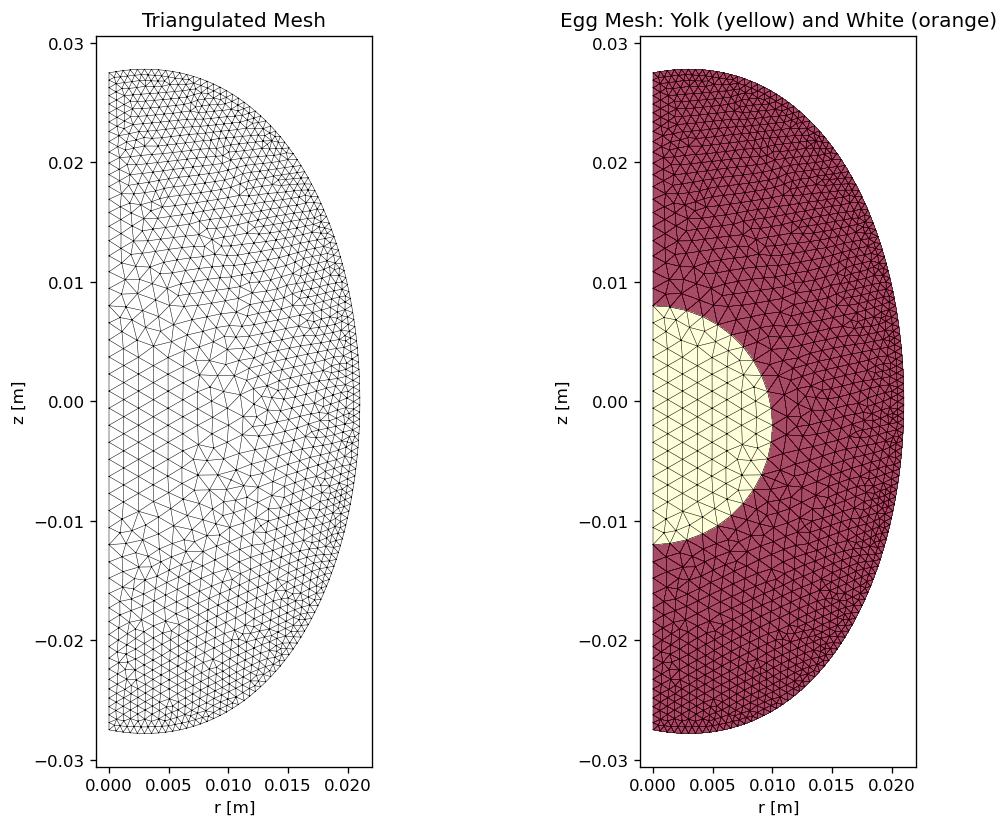

In [4]:
# --- Plot the mesh coloured by subdomain ---
basis = Basis(mesh, ElementTriP1())

fig, axes = plt.subplots(1, 2, figsize=(10, 7))

# Left: plain mesh
ax = axes[0]
ax.triplot(mesh.p[0], mesh.p[1], mesh.t.T, 'k-', lw=0.3)
ax.set_aspect('equal')
ax.set_xlabel('r [m]')
ax.set_ylabel('z [m]')
ax.set_title('Triangulated Mesh')

# Right: subdomains
ax = axes[1]
colors = np.zeros(mesh.t.shape[1])
if "yolk" in mesh.subdomains:
    colors[mesh.subdomains["yolk"]] = 1.0
ax.tripcolor(mesh.p[0], mesh.p[1], mesh.t.T, colors, cmap='YlOrRd_r', alpha=0.7)
ax.triplot(mesh.p[0], mesh.p[1], mesh.t.T, 'k-', lw=0.3)
ax.set_aspect('equal')
ax.set_xlabel('r [m]')
ax.set_ylabel('z [m]')
ax.set_title('Egg Mesh: Yolk (yellow) and White (orange)')

plt.tight_layout()
plt.show()

## Temperature-Dependent Material Properties

Egg white and yolk have different thermal properties, and these properties
change as the egg heats up.  The plots below show how density, thermal
conductivity, and specific heat vary with temperature for each region.

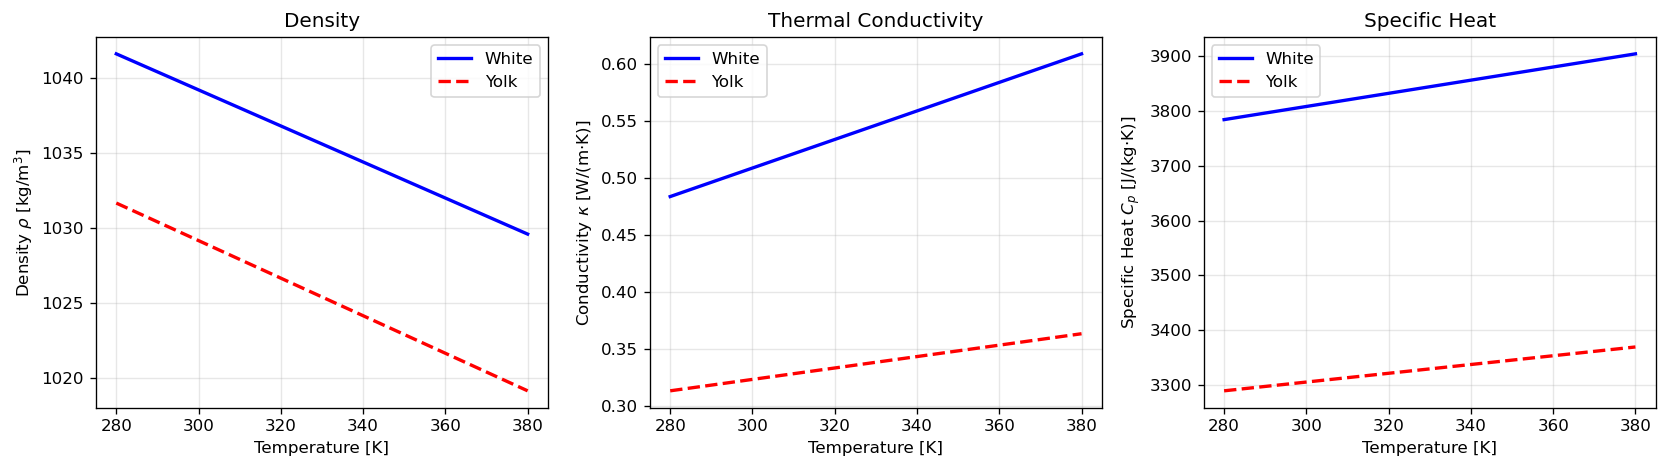

In [5]:
T_range = np.linspace(280, 380, 200)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Density
ax = axes[0]
ax.plot(T_range, [egg_white_properties.density(T) for T in T_range], 'b-', lw=2, label='White')
ax.plot(T_range, [egg_yolk_properties.density(T) for T in T_range], 'r--', lw=2, label='Yolk')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Density $\rho$ [kg/m$^3$]')
ax.set_title('Density')
ax.legend()
ax.grid(True, alpha=0.3)

# Conductivity
ax = axes[1]
ax.plot(T_range, [egg_white_properties.conductivity(T) for T in T_range], 'b-', lw=2, label='White')
ax.plot(T_range, [egg_yolk_properties.conductivity(T) for T in T_range], 'r--', lw=2, label='Yolk')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Conductivity $\kappa$ [W/(m$\cdot$K)]')
ax.set_title('Thermal Conductivity')
ax.legend()
ax.grid(True, alpha=0.3)

# Specific heat
ax = axes[2]
ax.plot(T_range, [egg_white_properties.specific_heat(T) for T in T_range], 'b-', lw=2, label='White')
ax.plot(T_range, [egg_yolk_properties.specific_heat(T) for T in T_range], 'r--', lw=2, label='Yolk')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Specific Heat $C_p$ [J/(kg$\cdot$K)]')
ax.set_title('Specific Heat')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Run Simulation

We set up the heat solver with:
- Multi-region material: yolk and white with temperature-dependent properties.
- Initial temperature: room temperature (20 C).
- Boundary condition: boiling water (100 C) on the egg shell.
- Time step: 1 s, total simulation time: 12 minutes (720 s).

In [6]:
material = {
    "yolk": egg_yolk_properties,
    "white": egg_white_properties,
}

solver = HeatSolver(
    mesh=mesh,
    material=material,
    T_init=T_ROOM,
    T_boundary=T_BOILING,
    dt=1.0,
)

print("Running realistic egg simulation (12 min, dt=1 s)...")
solver.run(t_end=720.0)
print("Done.")

Running realistic egg simulation (12 min, dt=1 s)...
  t =   60.0 s (1.0 min)  T_center = 20.0 °C
  t =  120.0 s (2.0 min)  T_center = 20.0 °C
  t =  180.0 s (3.0 min)  T_center = 21.0 °C
  t =  240.0 s (4.0 min)  T_center = 24.2 °C
  t =  300.0 s (5.0 min)  T_center = 29.6 °C
  t =  360.0 s (6.0 min)  T_center = 36.4 °C
  t =  420.0 s (7.0 min)  T_center = 43.8 °C
  t =  480.0 s (8.0 min)  T_center = 51.0 °C
  t =  540.0 s (9.0 min)  T_center = 57.7 °C
  t =  600.0 s (10.0 min)  T_center = 63.7 °C
  t =  660.0 s (11.0 min)  T_center = 69.0 °C
  t =  720.0 s (12.0 min)  T_center = 73.7 °C
Done.


## Center Temperature History

We track the temperature at the geometric centre of the egg (nearest mesh node
to the origin) and mark the key denaturation thresholds:
- **63 C** -- egg white begins to set
- **65 C** -- yolk begins to solidify
- **70 C** -- yolk fully hard

Compared to the simple spherical model from Notebook 01, the realistic geometry
and variable properties lead to a slightly different heating curve, especially
at later times when the yolk's lower conductivity slows heat penetration.

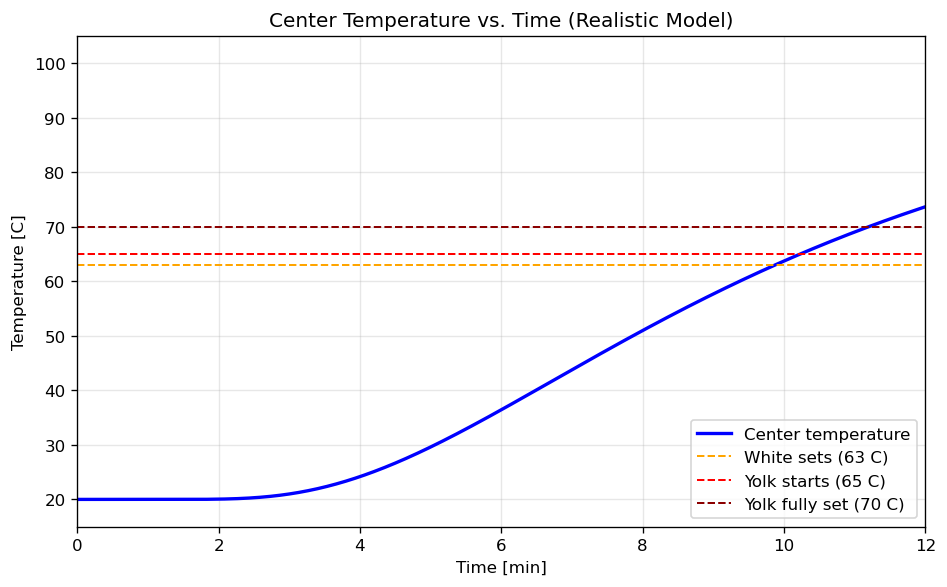

In [7]:
times_arr, T_center = solver.center_temperature_history()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(times_arr / 60, T_center, 'b-', lw=2, label='Center temperature')

# Denaturation thresholds
ax.axhline(63, color='orange', ls='--', lw=1.2, label='White sets (63 C)')
ax.axhline(65, color='red', ls='--', lw=1.2, label='Yolk starts (65 C)')
ax.axhline(70, color='darkred', ls='--', lw=1.2, label='Yolk fully set (70 C)')

ax.set_xlabel('Time [min]')
ax.set_ylabel('Temperature [C]')
ax.set_title('Center Temperature vs. Time (Realistic Model)')
ax.legend(loc='lower right')
ax.set_xlim(0, 12)
ax.set_ylim(15, 105)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Temperature Field Evolution

Snapshots of the temperature field at 2-minute intervals.  The denaturation
isotherms (63, 65, 70 C) are overlaid as contour lines to show the cooking
front propagating inward.

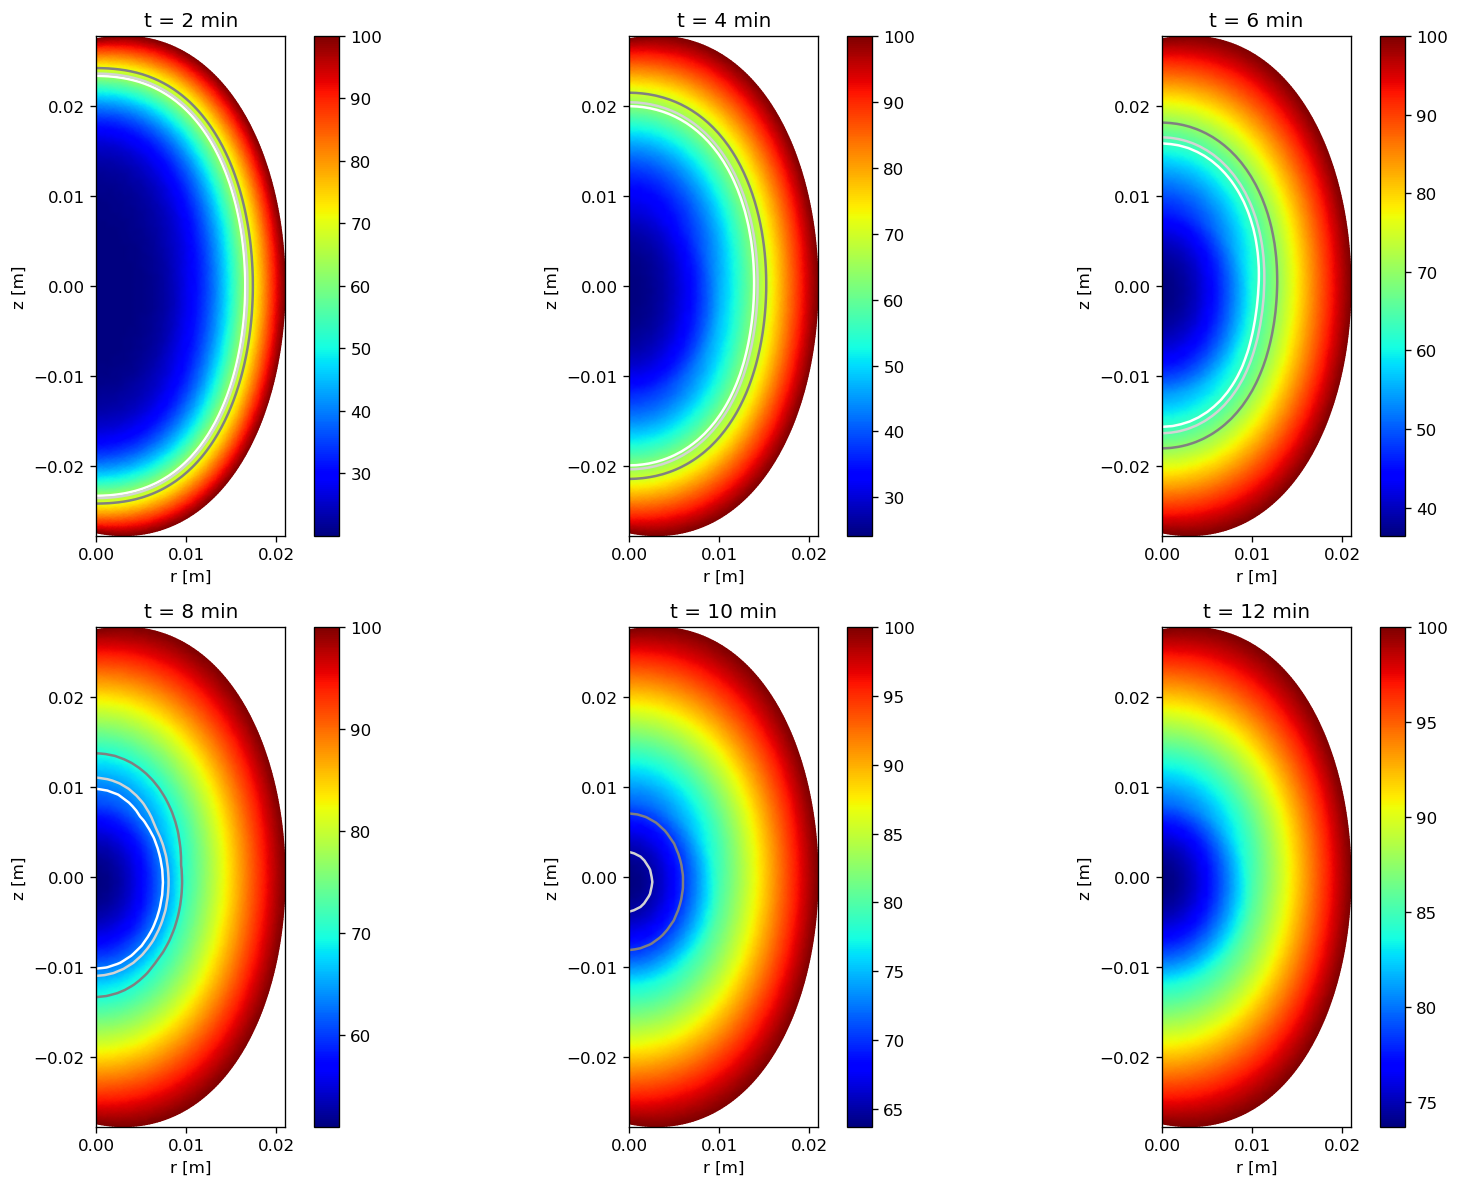

In [8]:
snapshot_times_min = [2, 4, 6, 8, 10, 12]

fig, axes = plt.subplots(2, 3, figsize=(14, 10))
axes = axes.ravel()

for idx, t_min in enumerate(snapshot_times_min):
    ax = axes[idx]
    step = int(t_min * 60)  # dt = 1 s
    if step >= len(solver.temperatures):
        step = len(solver.temperatures) - 1
    T_snapshot = solver.temperatures[step]
    T_celsius = T_snapshot - 273.15

    # Plot temperature field
    skfem_plot(basis, T_celsius, ax=ax, shading='gouraud', colorbar=True)

    # Denaturation contours
    try:
        ax.tricontour(
            mesh.p[0], mesh.p[1], mesh.t.T, T_celsius,
            levels=[63, 65, 70],
            colors=['white', 'lightgray', 'gray'],
            linewidths=1.5,
        )
    except ValueError:
        pass  # contour may fail if levels not in range

    ax.set_aspect('equal')
    ax.set_title(f't = {t_min} min')
    ax.set_xlabel('r [m]')
    ax.set_ylabel('z [m]')

plt.tight_layout()
plt.show()

## Denaturation Front

To understand how cooking progresses, we track the radial position of the
denaturation front along the midplane (z = 0).  As the egg cooks, the
63 C and 65 C isotherms move inward from the shell toward the centre.

In [9]:
from scipy.interpolate import interp1d

front_63 = []
front_65 = []

z_tol = 0.002  # tolerance for selecting nodes near z=0

for i, T in enumerate(solver.temperatures):
    T_c = T - 273.15
    # Find nodes near z=0
    mask = np.abs(mesh.p[1]) < z_tol
    r_vals = mesh.p[0, mask]
    T_vals = T_c[mask]
    # Sort by r
    order = np.argsort(r_vals)
    r_sorted = r_vals[order]
    T_sorted = T_vals[order]

    # 63 C front
    if len(r_sorted) > 2 and T_sorted[-1] >= 63:
        try:
            f = interp1d(T_sorted[::-1], r_sorted[::-1], bounds_error=False, fill_value=np.nan)
            front_63.append(float(f(63)))
        except Exception:
            front_63.append(np.nan)
    else:
        front_63.append(np.nan)

    # 65 C front
    if len(r_sorted) > 2 and T_sorted[-1] >= 65:
        try:
            f = interp1d(T_sorted[::-1], r_sorted[::-1], bounds_error=False, fill_value=np.nan)
            front_65.append(float(f(65)))
        except Exception:
            front_65.append(np.nan)
    else:
        front_65.append(np.nan)

front_63 = np.array(front_63)
front_65 = np.array(front_65)
t_arr = np.array(solver.times)

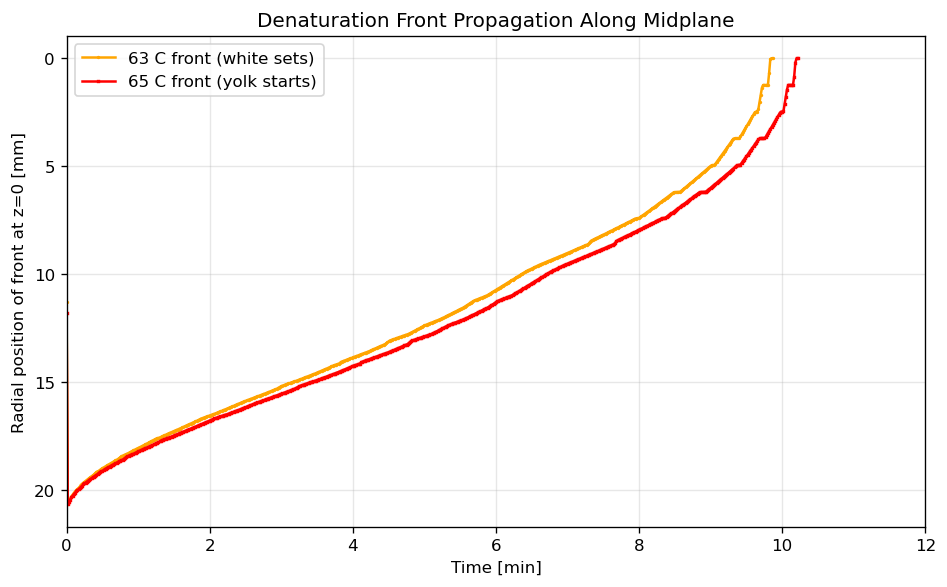

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

valid_63 = ~np.isnan(front_63)
valid_65 = ~np.isnan(front_65)

ax.plot(t_arr[valid_63] / 60, front_63[valid_63] * 1000, 'o-',
        color='orange', markersize=1, lw=1.5, label='63 C front (white sets)')
ax.plot(t_arr[valid_65] / 60, front_65[valid_65] * 1000, 's-',
        color='red', markersize=1, lw=1.5, label='65 C front (yolk starts)')

ax.set_xlabel('Time [min]')
ax.set_ylabel('Radial position of front at z=0 [mm]')
ax.set_title('Denaturation Front Propagation Along Midplane')
ax.legend()
ax.set_xlim(0, 12)
ax.grid(True, alpha=0.3)
ax.invert_yaxis()  # front moves inward (decreasing r)
plt.tight_layout()
plt.show()

## Summary

This realistic model captures several effects absent from the simple spherical
model:

- The **egg shape** leads to faster heating at the pointed end (shorter distance
  from shell to centre) compared to the blunt end.
- The **yolk's lower thermal conductivity** creates a visible delay in heat
  penetration once the cooking front reaches the yolk boundary.
- **Temperature-dependent properties** cause the effective thermal diffusivity to
  change as the egg heats, subtly affecting the cooking time.

The denaturation front plots show how the cooked region propagates inward and
give a quantitative picture of soft- vs. hard-boiled outcomes.

**Next: Notebook 03** will use this model for parameter studies -- varying initial
temperature (fridge vs. room), egg size, and cooking time to build a practical
guide for the perfect boiled egg.